In [1]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        path = os.path.join(root, file)
        print(file, round(os.path.getsize(path) / (1024 * 1024), 2), "MB")

The Lost World .txt 0.41 MB
Twenty Thousand Leagues Under the Sea.txt 0.59 MB
The Radio Planet.txt 0.4 MB
The Blue Star.txt 0.48 MB
The Island of Doctor Moreau.txt 0.24 MB
The Country of the Blind and Other Stories.txt 0.86 MB
The Time Machine  H.G. Well.txt 0.18 MB
The Invisible Man.txt 0.27 MB
A Journey to the Centre of the Earth.txt 0.49 MB
Frankenstein Or The Modern Prometheus by Mary Wollstonecraft Shelley.txt 0.41 MB
Anthem - Ayn Rand.txt 0.11 MB
The War of the Worlds.txt 0.33 MB
The Gods of Mars.txt 0.44 MB
The Lani People.txt 0.33 MB
Second Variety.txt 0.09 MB
The Marching Morons .txt 0.06 MB


In [2]:
import os
import glob

files = glob.glob("/kaggle/input/**/*.txt", recursive=True)

for path in files:
    if any(name in os.path.basename(path) for name in [
        "The Radio Planet",
        "The Blue Star",
        "Second Variety"
    ]):
        with open(path, "r", encoding="utf-8", errors="replace") as f:
            sample = f.read(1500)

        print("\nFILE:", os.path.basename(path))
        print(sample)
        print("\n" + "=" * 80)


FILE: The Radio Planet.txt
"It's too bad that Myles Cabot can't see this!" I exclaimed, as my eye
fell on the following item:

  Station has for several weeks been in receipt of fragmentary signals
  of extraordinarily long wave-length, Professor Hammond announced
  yesterday. So far as it has been possible to test the direction of the
  source of these waves, it appears that the direction has a twenty-four
  hour cycle, thus indicating that the origin of these waves is some
  point outside the earth._

  _The university authorities will express no opinion as to whether or
  not these messages come from Mars._

Myles, alone of all the radio engineers of my acquaintance, was
competent to surmount these difficulties, and thus enable the Cambridge
savants to receive with clearness the message from another planet.

Twelve months ago he would have been available, for he was then quietly
visiting at my farm, after five earth-years spent on the planet Venus,
where, by the aid of radio, he ha

In [3]:
import os
import glob

all_files = glob.glob("/kaggle/input/**/*.txt", recursive=True)

selected_names = [
    "Second Variety.txt",
    "The Blue Star.txt",
    "The Radio Planet.txt"
]

stories = {}

for path in all_files:
    filename = os.path.basename(path)

    if filename in selected_names:
        with open(path, "r", encoding="utf-8", errors="replace") as f:
            stories[filename] = f.read()

for name, content in stories.items():
    print(f"{name}: {len(content):,} characters, "
          f"{len(content.split()):,} words")

print("\nTotal words:", sum(len(s.split()) for s in stories.values()))

The Radio Planet.txt: 413,453 characters, 72,628 words
The Blue Star.txt: 480,808 characters, 88,024 words
Second Variety.txt: 87,199 characters, 15,229 words

Total words: 175881


In [4]:
import re

clean_stories = {}

for name, content in stories.items():
    # Normalize whitespace
    content = re.sub(r'\s+', ' ', content).strip()

    # Remove opening title/byline only for Second Variety
    if name == "Second Variety.txt":
        content = re.sub(
            r'^SECOND VARIETY\s+BY PHILIP K\. DICK\s+ILLUSTRATED BY EBEL\s+',
            '',
            content,
            flags=re.IGNORECASE
        )

    clean_stories[name] = content

clean_text = "\n\n".join(clean_stories.values())

print("Total characters:", f"{len(clean_text):,}")
print("Total words:", f"{len(clean_text.split()):,}")
print("\nPreview:\n")
print(clean_text[:2000])

Total characters: 971,009
Total words: 175,872

Preview:

"It's too bad that Myles Cabot can't see this!" I exclaimed, as my eye fell on the following item: Station has for several weeks been in receipt of fragmentary signals of extraordinarily long wave-length, Professor Hammond announced yesterday. So far as it has been possible to test the direction of the source of these waves, it appears that the direction has a twenty-four hour cycle, thus indicating that the origin of these waves is some point outside the earth._ _The university authorities will express no opinion as to whether or not these messages come from Mars._ Myles, alone of all the radio engineers of my acquaintance, was competent to surmount these difficulties, and thus enable the Cambridge savants to receive with clearness the message from another planet. Twelve months ago he would have been available, for he was then quietly visiting at my farm, after five earth-years spent on the planet Venus, where, by the aid of ra

In [5]:
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer

# Use a manageable vocabulary for training from scratch
vocab_size = 8000
sequence_length = 40

tokenizer = Tokenizer(
    num_words=vocab_size,
    oov_token="<UNK>"
)
tokenizer.fit_on_texts([clean_text])

encoded = tokenizer.texts_to_sequences([clean_text])[0]

# Chronological split: 80% train, 10% validation, 10% test
n = len(encoded)
train_end = int(n * 0.80)
val_end = int(n * 0.90)

train_tokens = encoded[:train_end]
val_tokens = encoded[train_end - sequence_length:val_end]
test_tokens = encoded[val_end - sequence_length:]

def make_sequences(tokens, seq_len):
    arr = np.asarray([
        tokens[i:i + seq_len + 1]
        for i in range(len(tokens) - seq_len)
    ], dtype=np.int32)

    return arr[:, :seq_len], arr[:, seq_len]

X_train, y_train = make_sequences(train_tokens, sequence_length)
X_val, y_val = make_sequences(val_tokens, sequence_length)
X_test, y_test = make_sequences(test_tokens, sequence_length)

print("Vocabulary size:", min(vocab_size, len(tokenizer.word_index) + 1))
print("Encoded tokens:", len(encoded))
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:", X_val.shape, "y_val:", y_val.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)

Vocabulary size: 8000
Encoded tokens: 178856
X_train: (143044, 40) y_train: (143044,)
X_val: (17886, 40) y_val: (17886,)
X_test: (17886, 40) y_test: (17886,)


In [6]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, Bidirectional, LSTM, GRU, Dense

tf.keras.utils.set_random_seed(42)

def build_model(model_type):
    model = Sequential([
        Input(shape=(sequence_length,)),
        Embedding(
            input_dim=vocab_size,
            output_dim=64,
            mask_zero=True
        )
    ])

    if model_type == "Simple RNN":
        model.add(SimpleRNN(64))
    elif model_type == "Bidirectional RNN":
        model.add(Bidirectional(SimpleRNN(32)))
    elif model_type == "LSTM":
        model.add(LSTM(64))
    elif model_type == "GRU":
        model.add(GRU(64))

    model.add(Dense(vocab_size, activation="softmax"))

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

model_types = [
    "Simple RNN",
    "Bidirectional RNN",
    "LSTM",
    "GRU"
]

models = {name: build_model(name) for name in model_types}

for name, model in models.items():
    print(f"\n{name}: {model.count_params():,} parameters")

2026-10-16 10:40:44.128000: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)



Simple RNN: 1,040,256 parameters

Bidirectional RNN: 1,038,208 parameters

LSTM: 1,065,024 parameters

GRU: 1,056,960 parameters


In [7]:
import time
import pandas as pd
from tensorflow.keras.callbacks import EarlyStopping

histories = {}
training_times = {}

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

for name, model in models.items():
    print(f"\nTraining {name}...")

    start = time.time()

    histories[name] = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=5,
        batch_size=128,
        callbacks=[early_stop],
        verbose=1
    )

    training_times[name] = time.time() - start
    print(f"{name} training time: {training_times[name]:.1f} seconds")


Training Simple RNN...
Epoch 1/5
1118/1118 ━━━━━━━━━━━━━━━━━━━━ 47s 40ms/step - accuracy: 0.0814 - loss: 6.5057 - val_accuracy: 0.1005 - val_loss: 6.0655
Epoch 2/5
1118/1118 ━━━━━━━━━━━━━━━━━━━━ 45s 40ms/step - accuracy: 0.1147 - loss: 5.9095 - val_accuracy: 0.1203 - val_loss: 5.7907
Epoch 3/5
1118/1118 ━━━━━━━━━━━━━━━━━━━━ 44s 40ms/step - accuracy: 0.1309 - loss: 5.6258 - val_accuracy: 0.1333 - val_loss: 5.6820
Epoch 4/5
1118/1118 ━━━━━━━━━━━━━━━━━━━━ 44s 39ms/step - accuracy: 0.1423 - loss: 5.4290 - val_accuracy: 0.1371 - val_loss: 5.6424
Epoch 5/5
1118/1118 ━━━━━━━━━━━━━━━━━━━━ 44s 39ms/step - accuracy: 0.1506 - loss: 5.2755 - val_accuracy: 0.1391 - val_loss: 5.6359
Simple RNN training time: 224.4 seconds

Training Bidirectional RNN...
Epoch 1/5
1118/1118 ━━━━━━━━━━━━━━━━━━━━ 53s 45ms/step - accuracy: 0.0806 - loss: 6.5088 - val_accuracy: 0.0901 - val_loss: 6.1208
Epoch 2/5
1118/1118 ━━━━━━━━━━━━━━━━━━━━ 50s 45ms/step - accuracy: 0.1120 - loss: 5.9539 - val_accuracy: 0.1146 - val_l

In [8]:
import numpy as np
import pandas as pd

results = []

for name, model in models.items():
    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

    results.append({
        "Model": name,
        "Test Loss": loss,
        "Test Accuracy (%)": accuracy * 100,
        "Perplexity": np.exp(min(loss, 700)),
        "Training Time (s)": training_times[name],
        "Epochs": len(histories[name].history["loss"])
    })

results_df = pd.DataFrame(results)
display(results_df.round(3))

,Model,Test Loss,Test Accuracy (%),Perplexity,Training Time (s),Epochs
0,Simple RNN,6.681,10.293,797.319,224.355,5
1,Bidirectional RNN,6.821,7.386,917.306,103.313,2
2,LSTM,6.902,7.101,993.815,170.976,2
3,GRU,6.811,7.173,907.492,170.443,2


In [9]:
for name, history in histories.items():
    print(f"\n{name}")
    for epoch, (train_loss, val_loss) in enumerate(
        zip(history.history["loss"], history.history["val_loss"]), start=1
    ):
        print(
            f"Epoch {epoch}: "
            f"train loss = {train_loss:.4f}, "
            f"validation loss = {val_loss:.4f}"
        )


Simple RNN
Epoch 1: train loss = 6.5057, validation loss = 6.0655
Epoch 2: train loss = 5.9095, validation loss = 5.7907
Epoch 3: train loss = 5.6258, validation loss = 5.6820
Epoch 4: train loss = 5.4290, validation loss = 5.6424
Epoch 5: train loss = 5.2755, validation loss = 5.6359

Bidirectional RNN
Epoch 1: train loss = 6.5088, validation loss = 6.1208
Epoch 2: train loss = 5.9539, validation loss = 5.8692

LSTM
Epoch 1: train loss = 6.5549, validation loss = 6.2102
Epoch 2: train loss = 6.0870, validation loss = 6.0025

GRU
Epoch 1: train loss = 6.5098, validation loss = 6.1122
Epoch 2: train loss = 5.9833, validation loss = 5.8862


In [10]:
from tensorflow.keras.callbacks import EarlyStopping
import time

for name, model in models.items():
    print(f"\nContinuing {name}...")

    start = time.time()

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=8,  # up to 8 additional epochs
        batch_size=128,
        callbacks=[
            EarlyStopping(
                monitor="val_loss",
                patience=3,
                restore_best_weights=True
            )
        ],
        verbose=1
    )

    # Keep the continuation history
    histories[name + " continued"] = history
    training_times[name] += time.time() - start


Continuing Simple RNN...
Epoch 1/8
1118/1118 ━━━━━━━━━━━━━━━━━━━━ 46s 41ms/step - accuracy: 0.1576 - loss: 5.1464 - val_accuracy: 0.1404 - val_loss: 5.6441
Epoch 2/8
1118/1118 ━━━━━━━━━━━━━━━━━━━━ 46s 41ms/step - accuracy: 0.1647 - loss: 5.0299 - val_accuracy: 0.1417 - val_loss: 5.6610
Epoch 3/8
1118/1118 ━━━━━━━━━━━━━━━━━━━━ 47s 42ms/step - accuracy: 0.1722 - loss: 4.9219 - val_accuracy: 0.1398 - val_loss: 5.6806
Epoch 4/8
1118/1118 ━━━━━━━━━━━━━━━━━━━━ 45s 40ms/step - accuracy: 0.1780 - loss: 4.8200 - val_accuracy: 0.1377 - val_loss: 5.7099

Continuing Bidirectional RNN...
Epoch 1/8
1118/1118 ━━━━━━━━━━━━━━━━━━━━ 52s 46ms/step - accuracy: 0.1111 - loss: 5.9635 - val_accuracy: 0.1146 - val_loss: 5.8919
Epoch 2/8
1118/1118 ━━━━━━━━━━━━━━━━━━━━ 50s 45ms/step - accuracy: 0.1273 - loss: 5.6847 - val_accuracy: 0.1257 - val_loss: 5.7963
Epoch 3/8
1118/1118 ━━━━━━━━━━━━━━━━━━━━ 49s 43ms/step - accuracy: 0.1374 - loss: 5.4658 - val_accuracy: 0.1274 - val_loss: 5.7704
Epoch 4/8
1118/1118 ━━━━

In [11]:
import numpy as np

def generate_text(model, seed_text, num_words=100, temperature=0.7):
    generated = seed_text.lower().split()

    for _ in range(num_words):
        context = " ".join(generated[-sequence_length:])
        ids = tokenizer.texts_to_sequences([context])[0]
        ids = ids[-sequence_length:]
        ids = [0] * (sequence_length - len(ids)) + ids

        probs = model.predict(np.array([ids]), verbose=0)[0].astype(np.float64)
        probs[0] = 0

        # Temperature sampling
        probs = np.log(probs + 1e-12) / temperature
        probs = np.exp(probs - np.max(probs))
        probs /= probs.sum()

        next_id = np.random.choice(len(probs), p=probs)
        next_word = tokenizer.index_word.get(next_id, "")

        if next_word:
            generated.append(next_word)

    return " ".join(generated)

seed = "the Russian soldier made his way"

for name, model in models.items():
    print(f"\n{'='*25} {name} {'='*25}")
    print(generate_text(model, seed, num_words=80, temperature=0.7))


========================= Simple RNN =========================
the russian soldier made his way to bees he asked in the <UNK> ” said lalette <UNK> “ah me you ” he said when he had reached the ant man had returned to the count the maid and the kinds of pain in the service of the god of pedigree and all the princess at the list of course they will need the young man at the new son of the window of this of different beyond the <UNK> doggo made up out the same <UNK>

========================= Bidirectional RNN =========================
the russian soldier made his way she looked for the green world from the exact glass of which they could am no most of the door the pretty wall for our own blue star to the rifle of law they himself ser me in them a cat from the back of the dream from the princess and the other must try to be their old precipitous status of the court in the mountains in the <UNK> on the room with cleudi’s eyes for that and could

========================= LSTM =============

In [12]:
import numpy as np
import time

results = []

for name, model in models.items():
    test_loss, test_accuracy = model.evaluate(
        X_test, y_test, batch_size=128, verbose=0
    )

    perplexity = np.exp(min(test_loss, 700))

    results.append({
        "Model": name,
        "Test Loss": round(test_loss, 4),
        "Accuracy (%)": round(test_accuracy * 100, 2),
        "Perplexity": round(perplexity, 2),
        "Training Time (seconds)": round(training_times[name], 2)
    })

import pandas as pd
results_df = pd.DataFrame(results)
display(results_df)

,Model,Test Loss,Accuracy (%),Perplexity,Training Time (seconds)
0,Simple RNN,6.7376,10.29,843.50,408.02
1,Bidirectional RNN,6.7372,9.62,843.22,400.94
2,LSTM,6.9438,9.80,1036.68,853.86
3,GRU,6.7711,10.09,872.31,879.94


In [13]:
temperatures = [0.3, 0.7, 1.0]
seed = "the Russian soldier made his way"

for name, model in models.items():
    print(f"\n{'='*60}\n{name}\n{'='*60}")

    for temp in temperatures:
        np.random.seed(42)
        generated = generate_text(
            model,
            seed_text=seed,
            num_words=60,
            temperature=temp
        )

        print(f"\nTemperature: {temp}")
        print(generated)


Simple RNN

Temperature: 0.3
the russian soldier made his way to his feet and <UNK> the <UNK> of the same <UNK> of the <UNK> of the earth man had been a <UNK> of the <UNK> of the plane and <UNK> and the <UNK> of the palace of the vairkings and the earth man were <UNK> in the <UNK> of the arsenal and then he had been <UNK> to the <UNK>

Temperature: 0.7
the russian soldier made his way to bees he asked in the <UNK> ” said lalette <UNK> “ah me you ” he said when he had reached the ant man had returned to the count the maid and the kinds of pain in the service of the god of pedigree and all the princess at the list of course they will need the young man at

Temperature: 1.0
the russian soldier made his way that captain’s adventures but he had in interest against their <UNK> monsters my way to him it is so for so a men but like these but she turned the bottle of the skeleton crooning land on the skies as a common of interview to either his antennae from the delegation rodvard penalties “n

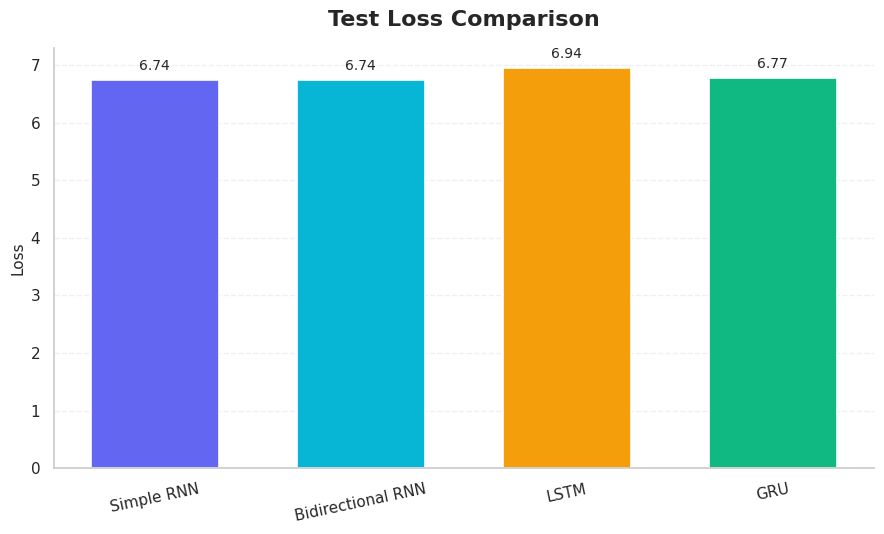

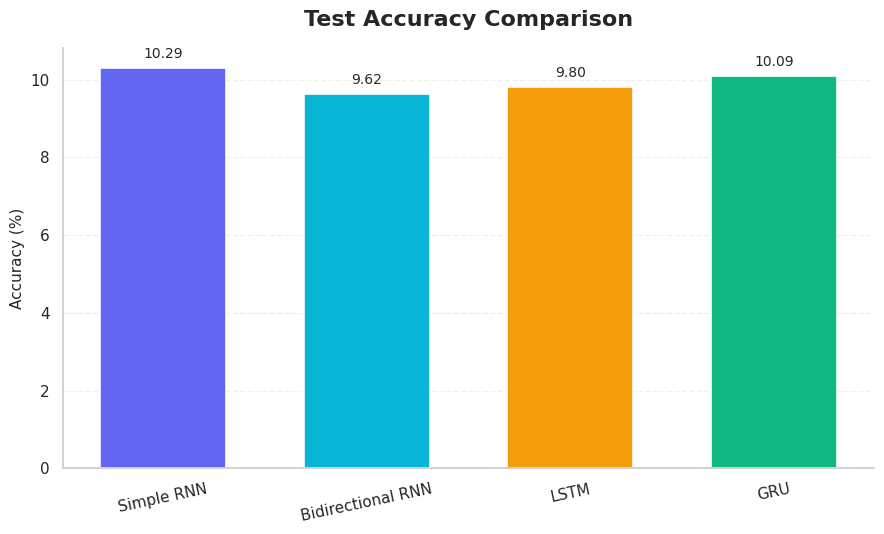

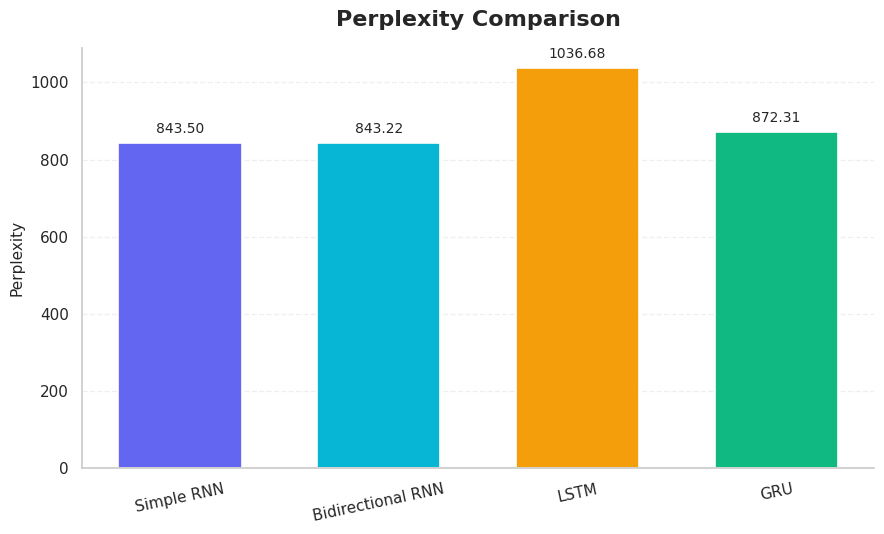

Saved all 3 colour-coded graphs!


In [15]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("assignment_results", exist_ok=True)

# Consistent colour for each model
model_colors = {
    "Simple RNN": "#6366F1",
    "Bidirectional RNN": "#06B6D4",
    "LSTM": "#F59E0B",
    "GRU": "#10B981"
}

sns.set_theme(style="whitegrid", context="notebook")

metrics = [
    ("Test Loss", "Test Loss Comparison", "Loss"),
    ("Accuracy (%)", "Test Accuracy Comparison", "Accuracy (%)"),
    ("Perplexity", "Perplexity Comparison", "Perplexity")
]

for column, title, ylabel in metrics:
    fig, ax = plt.subplots(figsize=(9, 5.5))

    colors = [model_colors[m] for m in results_df["Model"]]
    bars = ax.bar(
        results_df["Model"],
        results_df[column],
        color=colors,
        width=0.62,
        edgecolor="white",
        linewidth=1.2
    )

    ax.set_title(title, fontsize=16, fontweight="bold", pad=16)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=12)
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.grid(axis="x", visible=False)

    # Display values above bars
    ax.bar_label(bars, fmt="%.2f", padding=5, fontsize=10)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    filename = column.lower().replace(" (%)", "").replace(" ", "_")
    plt.savefig(
        f"assignment_results/{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

print("Saved all 3 colour-coded graphs!")

In [16]:
import pandas as pd
import numpy as np
import os

os.makedirs("assignment_results", exist_ok=True)

temperatures = [0.3, 0.7, 1.0]
seed = "the Russian soldier made his way"
sample_results = []

for name, model in models.items():
    for temp in temperatures:
        np.random.seed(42)

        generated = generate_text(
            model,
            seed_text=seed,
            num_words=100,
            temperature=temp
        )

        sample_results.append({
            "Model": name,
            "Seed": seed,
            "Temperature": temp,
            "Generated Text": generated
        })

samples_df = pd.DataFrame(sample_results)
samples_df.to_csv(
    "assignment_results/generated_samples.csv",
    index=False
)

display(samples_df)
print("Generated samples saved successfully!")

,Model,Seed,Temperature,Generated Text
0,Simple RNN,the Russian soldier made his way,0.3,the russian soldier made his way to his feet a...
1,Simple RNN,the Russian soldier made his way,0.7,the russian soldier made his way to bees he as...
2,Simple RNN,the Russian soldier made his way,1.0,the russian soldier made his way that captain’...
3,Bidirectional RNN,the Russian soldier made his way,0.3,the russian soldier made his way to be a <UNK>...
4,Bidirectional RNN,the Russian soldier made his way,0.7,the russian soldier made his way to barred his...
5,Bidirectional RNN,the Russian soldier made his way,1.0,the russian soldier made his way you introduct...
6,LSTM,the Russian soldier made his way,0.3,the russian soldier made his way to her hand t...
7,LSTM,the Russian soldier made his way,0.7,the russian soldier made his way up guard from...
8,LSTM,the Russian soldier made his way,1.0,the russian soldier made his way whether stand...
9,GRU,the Russian soldier made his way,0.3,the russian soldier made his way and nearly no...


Generated samples saved successfully!
